Medium vs Hard pace: -0.11 s (SE 0.07)
Soft vs Hard pace:   0.17 s (SE 0.11)
Tyre wear: 0.043 s/lap (SE 0.007)

Strategies tested: 2730

Top 8 strategies (dry 52-lap race):
 stops strategy  mean_s  sd_s  P_best  gap_to_best_s
     1  H24-M28   47.18  5.47    0.05           0.00
     1  M27-H25   47.21  5.40    0.06           0.03
     1  H25-M27   47.23  5.41    0.06           0.05
     1  M28-H24   47.25  5.54    0.06           0.07
     1  M26-H26   47.31  5.39    0.06           0.13
     1  H23-M29   47.32  5.51    0.05           0.14
     1  H26-M26   47.36  5.44    0.05           0.18
     1  M29-H23   47.39  5.65    0.05           0.21

Best strategy for each number of stops:
 stops        strategy  mean_s  sd_s  P_best  gap_to_best_s
     1         H24-M28   47.18  5.47    0.05           0.00
     2     M20-M17-H15   58.53  5.29    0.00          11.35
     3 M14-M14-M14-H10   75.09  5.73    0.00          27.91

Share of simulated races won by each stop count:
stops
1    0.999
2 

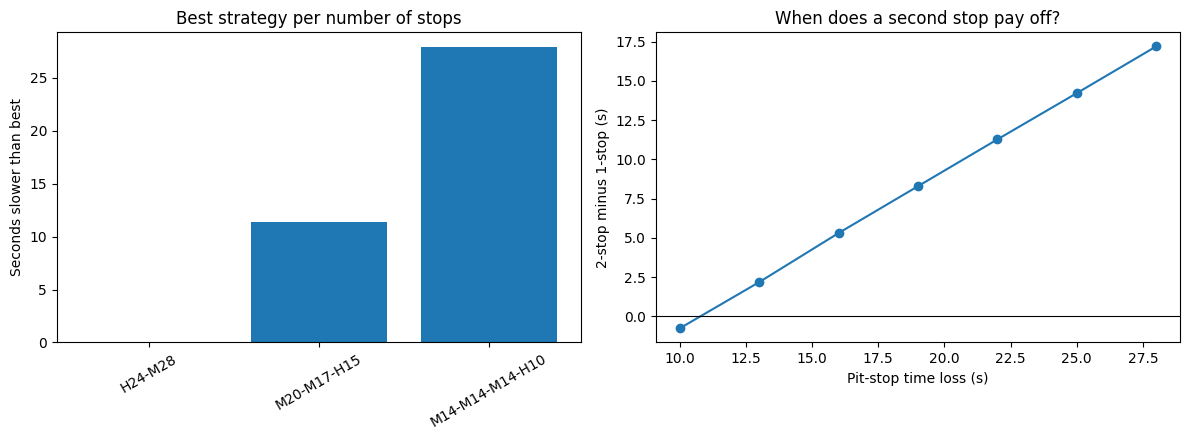

In [14]:
import itertools

# ---- A. fit pace offsets + one common wear rate, with uncertainty ----
f_c = "fc ~ C(dr) + C(compound) + tyre_age + post_rain"
r2 = smf.ols(f_c, data=sil).fit(cov_type="cluster",
                                cov_kwds={"groups": pd.factorize(sil["grp"])[0]})
names = ["C(compound)[T.MEDIUM]", "C(compound)[T.SOFT]", "tyre_age"]
mu = r2.params[names].values
cov = r2.cov_params().loc[names, names].values
print("Medium vs Hard pace: %.2f s (SE %.2f)" % (mu[0], np.sqrt(cov[0, 0])))
print("Soft vs Hard pace:   %.2f s (SE %.2f)" % (mu[1], np.sqrt(cov[1, 1])))
print("Tyre wear: %.3f s/lap (SE %.3f)" % (mu[2], np.sqrt(cov[2, 2])))

# ---- B. Monte Carlo strategy simulation ----
TOTAL, MAXSTINT, MINSTINT = 52, 31, 8
PIT, PIT_SD, N = 22.0, 2.5, 4000
rng = np.random.default_rng(0)

draws = rng.multivariate_normal(mu, cov, N, check_valid="ignore")
off = {"HARD": np.zeros(N), "MEDIUM": draws[:, 0], "SOFT": draws[:, 1]}
wear = draws[:, 2]

def splits(k, step):
    out = []
    def rec(parts, left, n):
        if n == 1:
            if MINSTINT <= left <= MAXSTINT:
                out.append(tuple(parts + [left]))
            return
        for a in range(MINSTINT, MAXSTINT + 1, step):
            if left - a >= MINSTINT * (n - 1):
                rec(parts + [a], left - a, n - 1)
    rec([], TOTAL, k)
    return out

def race_time(comps, lens, pit_mean):
    t = np.zeros(N)
    for c, n in zip(comps, lens):
        t += off[c] * n + wear * n * (n - 1) / 2
    stops = len(lens) - 1
    t += rng.normal(pit_mean, PIT_SD, (N, stops)).sum(axis=1)
    return t

strats = []
for stops, step in {1: 1, 2: 3, 3: 6}.items():
    for lens in splits(stops + 1, step):
        for comps in itertools.product(["SOFT", "MEDIUM", "HARD"], repeat=stops + 1):
            if len(set(comps)) >= 2:          # rule: use at least two compounds
                strats.append((stops, comps, lens))
print("\nStrategies tested:", len(strats))

def run(pit_mean):
    return np.array([race_time(c, l, pit_mean) for _, c, l in strats])

T = run(PIT)
p_best = np.bincount(T.argmin(axis=0), minlength=len(strats)) / N
tab = pd.DataFrame({
    "stops": [s for s, _, _ in strats],
    "strategy": ["-".join(f"{c[0]}{n}" for c, n in zip(cs, ls)) for _, cs, ls in strats],
    "mean_s": T.mean(axis=1), "sd_s": T.std(axis=1), "P_best": p_best})
tab["gap_to_best_s"] = tab["mean_s"] - tab["mean_s"].min()
tab = tab.sort_values("mean_s")

print("\nTop 8 strategies (dry 52-lap race):")
print(tab.head(8).round(2).to_string(index=False))
best_by_stops = tab.groupby("stops").head(1).sort_values("stops")
print("\nBest strategy for each number of stops:")
print(best_by_stops.round(2).to_string(index=False))
print("\nShare of simulated races won by each stop count:")
print(tab.groupby("stops")["P_best"].sum().round(3).to_string())

print("\nSensitivity to pit-stop time loss (best 2-stop minus best 1-stop):")
sens = []
stp = np.array([s for s, _, _ in strats])
for pm in [10, 13, 16, 19, 22, 25, 28]:
    Tm = run(pm).mean(axis=1)
    gap = Tm[stp == 2].min() - Tm[stp == 1].min()
    sens.append((pm, gap))
    print(f"  pit loss {pm} s: {gap:+.1f} s  ({'1-stop' if gap > 0 else '2-stop'} faster)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(best_by_stops["strategy"], best_by_stops["mean_s"] - best_by_stops["mean_s"].min())
ax[0].set_ylabel("Seconds slower than best")
ax[0].set_title("Best strategy per number of stops")
ax[0].tick_params(axis="x", rotation=30)
xs, ys = zip(*sens)
ax[1].plot(xs, ys, marker="o")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xlabel("Pit-stop time loss (s)")
ax[1].set_ylabel("2-stop minus 1-stop (s)")
ax[1].set_title("When does a second stop pay off?")
plt.tight_layout()
plt.show()

In [12]:
FUEL = 0.0624   # s per lap, average of the three dry-race estimates

sil = pool[pool["race"].isin(["Silverstone23", "Silverstone24"])].copy()
sil["fc"] = sil["lap_duration"] + FUEL * sil["lap_number"]     # fuel-corrected lap time
sil["compound"] = sil["compound"].astype(str)
sil["grp"] = sil["dr"] + "_" + sil["stint"].astype(str)

f_sil = "fc ~ C(dr) + C(compound) + C(compound):tyre_age + post_rain"
r = smf.ols(f_sil, data=sil).fit(cov_type="cluster",
                                 cov_kwds={"groups": pd.factorize(sil["grp"])[0]})
ci = r.conf_int()

def show(keys, title):
    rows = [i for i in r.params.index if any(k in i for k in keys)]
    t = pd.DataFrame({"seconds": r.params[rows], "low95": ci.loc[rows, 0],
                      "high95": ci.loc[rows, 1]}).round(3)
    print(title); print(t.to_string()); print()

show(["T.MEDIUM]", "T.SOFT]"], "Pace vs HARD at tyre age 0 (negative = faster):")
show(["tyre_age"], "Tyre wear (seconds lost per lap of tyre age):")
print("post_rain:", round(r.params["post_rain"], 2), "s")
print()
print("Laps per compound:")
print(sil.groupby(["race", "compound"]).size().unstack(fill_value=0))
print()
print("Longest stint seen (tyre age):")
print(sil.groupby("compound")["tyre_age"].max())

Pace vs HARD at tyre age 0 (negative = faster):
                       seconds  low95  high95
C(compound)[T.MEDIUM]   -0.167 -0.655   0.321
C(compound)[T.SOFT]      0.267 -0.482   1.016

Tyre wear (seconds lost per lap of tyre age):
                              seconds  low95  high95
C(compound)[HARD]:tyre_age      0.042  0.001   0.083
C(compound)[MEDIUM]:tyre_age    0.046  0.032   0.060
C(compound)[SOFT]:tyre_age      0.034 -0.005   0.072

post_rain: -0.37 s

Laps per compound:
compound       HARD  MEDIUM  SOFT
race                             
Silverstone23   116     439   250
Silverstone24    36     331   132

Longest stint seen (tyre age):
compound
HARD      30.0
MEDIUM    31.0
SOFT      29.0
Name: tyre_age, dtype: float64


In [11]:
pool["grp"] = pool["dr"] + "_" + pool["stint"].astype(str)

def tyre_table(data, formula, label):
    data = data.copy()
    data["compound"] = data["compound"].astype(str)
    r = smf.ols(formula, data=data).fit(cov_type="cluster",
                                        cov_kwds={"groups": pd.factorize(data["grp"])[0]})
    ci = r.conf_int()
    rows = [i for i in r.params.index if "tyre_age" in i]
    t = pd.DataFrame({"s_per_lap": r.params[rows], "low95": ci.loc[rows, 0],
                      "high95": ci.loc[rows, 1]}).round(3)
    t.index = [i.replace("C(compound)[", "").replace("]:tyre_age", "") for i in t.index]
    print(label); print(t.to_string()); print()

f_one = "lap_duration ~ C(name_acronym) + C(compound) + C(compound):tyre_age + lap_number"
for race in ["Bahrain24", "Spain24", "Silverstone23"]:
    tyre_table(pool[pool["race"] == race], f_one, f"{race} alone")

dry = pool[pool["race"] != "Silverstone24"]
f_dry = "lap_duration ~ C(dr) + C(compound) + C(compound):tyre_age + C(race):lap_number"
tyre_table(dry, f_dry, "Pooled, 3 dry races, cluster-robust intervals")

Bahrain24 alone
      s_per_lap  low95  high95
HARD      0.110  0.101   0.119
SOFT      0.129  0.105   0.154

Spain24 alone
        s_per_lap  low95  high95
HARD        0.078  0.064   0.092
MEDIUM      0.082  0.070   0.095
SOFT        0.086  0.065   0.106

Silverstone23 alone
        s_per_lap  low95  high95
HARD        0.020 -0.013   0.053
MEDIUM      0.017  0.008   0.026
SOFT       -0.007 -0.058   0.045

Pooled, 3 dry races, cluster-robust intervals
        s_per_lap  low95  high95
HARD        0.085  0.073   0.097
MEDIUM      0.047  0.036   0.058
SOFT        0.071  0.049   0.092



In [10]:
import warnings
warnings.filterwarnings("ignore")

def get_sk(endpoint, sk):
    for attempt in range(6):
        r = requests.get(f"{BASE}/{endpoint}", params={"session_key": sk})
        if r.status_code == 200:
            return pd.DataFrame(r.json())
        time.sleep(3 * (attempt + 1))
    raise RuntimeError(f"{endpoint} failed: {r.status_code}")

def build_clean(sk, label):
    L = get_sk("laps", sk); time.sleep(1)
    S = get_sk("stints", sk); time.sleep(1)
    P = get_sk("pit", sk); time.sleep(1)
    D = get_sk("drivers", sk); time.sleep(1)
    R = get_sk("race_control", sk); time.sleep(1)
    L = L.dropna(subset=["lap_duration"]).copy()
    parts = []
    for _, s in S.iterrows():
        if pd.isna(s["lap_start"]) or pd.isna(s["lap_end"]) or pd.isna(s["tyre_age_at_start"]):
            continue
        mk = (L["driver_number"] == s["driver_number"])
        mk = mk & (L["lap_number"] >= s["lap_start"]) & (L["lap_number"] <= s["lap_end"])
        sub = L[mk].copy()
        sub["compound"] = s["compound"]
        sub["stint"] = s["stint_number"]
        sub["tyre_age"] = s["tyre_age_at_start"] + (sub["lap_number"] - s["lap_start"])
        parts.append(sub)
    x = pd.concat(parts)
    x = x.merge(D[["driver_number", "name_acronym"]].drop_duplicates("driver_number"),
                on="driver_number", how="left")
    pit_set = set(zip(P["driver_number"], P["lap_number"]))
    x["is_in_lap"] = [(a, b) in pit_set for a, b in zip(x["driver_number"], x["lap_number"])]
    sc = R[R["message"].str.contains("SAFETY CAR|VSC|VIRTUAL", case=False, na=False)]
    x["sc_lap"] = x["lap_number"].isin(set(sc["lap_number"].dropna().astype(int)))
    k = ((x["lap_number"] > 1) & (~x["is_pit_out_lap"].astype(bool)) & (~x["is_in_lap"])
         & (~x["sc_lap"]) & (x["compound"].isin(["SOFT", "MEDIUM", "HARD"])))
    x = x[k].copy()
    med = x.groupby(["driver_number", "stint"])["lap_duration"].transform("median")
    x = x[x["lap_duration"] < 1.04 * med].copy()
    x["race"] = label
    print(label, "| clean laps:", len(x), "| SC/VSC messages:", len(sc))
    return x

races = [(2024, "Sakhir", "Bahrain24"),
         (2024, "Catalunya", "Spain24"),
         (2023, "Silverstone", "Silverstone23")]
frames = []
for yr, circ, label in races:
    sess = requests.get(f"{BASE}/sessions", params={
        "year": yr, "session_name": "Race", "circuit_short_name": circ}).json()
    time.sleep(1)
    if not sess:
        print("not found:", yr, circ)
        continue
    frames.append(build_clean(sess[0]["session_key"], label))

# Silverstone 2024: reuse the cleaned data, dry windows only
s24 = clean[(clean["lap_number"] <= 19) | (clean["lap_number"] >= 42)].copy()
s24["race"] = "Silverstone24"
frames.append(s24)

pool = pd.concat(frames, ignore_index=True)
pool["post_rain"] = ((pool["race"] == "Silverstone24") & (pool["lap_number"] >= 42)).astype(int)
pool["dr"] = pool["race"] + "_" + pool["name_acronym"].astype(str)
pool["compound"] = pd.Categorical(pool["compound"])
pool["tyre_age"] = pool["tyre_age"].astype(float)

print()
print(pool.groupby(["race", "compound"]).size().unstack(fill_value=0))
print()

f_pool = ("lap_duration ~ C(dr) + C(compound) + C(compound):tyre_age"
          " + C(race):lap_number + post_rain")
rp = smf.ols(f_pool, data=pool).fit()
ci = rp.conf_int()
rows = [i for i in rp.params.index if "tyre_age" in i or "lap_number" in i or i == "post_rain"]
tab = pd.DataFrame({"seconds": rp.params[rows], "low95": ci.loc[rows, 0],
                    "high95": ci.loc[rows, 1]}).round(4)
print(tab.to_string())
print("R-squared:", round(rp.rsquared, 3))

Bahrain24 | clean laps: 1024 | SC/VSC messages: 0
Spain24 | clean laps: 1198 | SC/VSC messages: 0
Silverstone23 | clean laps: 805 | SC/VSC messages: 3

compound       HARD  MEDIUM  SOFT
race                             
Bahrain24       731       0   293
Silverstone23   116     439   250
Silverstone24    36     331   132
Spain24         340     401   457

                                   seconds   low95  high95
C(compound)[HARD]:tyre_age          0.0847  0.0793  0.0902
C(compound)[MEDIUM]:tyre_age        0.0477  0.0418  0.0535
C(compound)[SOFT]:tyre_age          0.0720  0.0643  0.0796
C(race)[Bahrain24]:lap_number      -0.0650 -0.0676 -0.0624
C(race)[Silverstone23]:lap_number  -0.0668 -0.0701 -0.0636
C(race)[Silverstone24]:lap_number   0.0283  0.0147  0.0419
C(race)[Spain24]:lap_number        -0.0554 -0.0577 -0.0532
post_rain                          -3.5820 -4.0946 -3.0694
R-squared: 0.992


In [9]:
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupKFold

# dry-start window and post-rain window only (skip the rain and drying transition)
m = clean[(clean["lap_number"] <= 19) | (clean["lap_number"] >= 42)].copy()
m["post_rain"] = (m["lap_number"] >= 42).astype(int)
m["driver"] = pd.Categorical(m["name_acronym"])
m["compound"] = pd.Categorical(m["compound"])
m["tyre_age"] = m["tyre_age"].astype(float)
print("Laps used:", len(m))
print(m["compound"].value_counts().to_string())
print()

# 1. full model: one tyre-wear slope per compound
f_full = "lap_duration ~ C(driver) + C(compound) + C(compound):tyre_age + lap_number + post_rain"
res = smf.ols(f_full, data=m).fit()
ci = res.conf_int()
rows = [i for i in res.params.index
        if "tyre_age" in i or i in ["lap_number", "post_rain"]]
out = pd.DataFrame({"seconds": res.params[rows],
                    "low95": ci.loc[rows, 0],
                    "high95": ci.loc[rows, 1]}).round(4)
print("Effect per extra lap of tyre age / lap number (seconds):")
print(out.to_string())
print("R-squared:", round(res.rsquared, 3))
print()

# 2. out-of-sample test: does tyre age help predict unseen laps?
m["grp"] = m["driver"].astype(str) + "_" + m["stint"].astype(str)
f_base = "lap_duration ~ C(driver) + C(compound) + lap_number + post_rain"
gkf = GroupKFold(n_splits=5)
err_full, err_base = [], []
for tr, te in gkf.split(m, groups=m["grp"]):
    a, b = m.iloc[tr], m.iloc[te]
    pf = smf.ols(f_full, data=a).fit().predict(b)
    pb = smf.ols(f_base, data=a).fit().predict(b)
    err_full.append((b["lap_duration"] - pf) ** 2)
    err_base.append((b["lap_duration"] - pb) ** 2)
rmse_full = np.sqrt(pd.concat(err_full).mean())
rmse_base = np.sqrt(pd.concat(err_base).mean())
print("Out-of-sample RMSE (seconds), whole stints held out:")
print("  without tyre age:", round(rmse_base, 3))
print("  with tyre age:   ", round(rmse_full, 3))
print("  improvement:     ", round(100 * (1 - rmse_full / rmse_base), 1), "%")

Laps used: 499
compound
MEDIUM    331
SOFT      132
HARD       36

Effect per extra lap of tyre age / lap number (seconds):
                              seconds   low95  high95
C(compound)[HARD]:tyre_age     0.0267 -0.0543  0.1077
C(compound)[MEDIUM]:tyre_age   0.0250 -0.0309  0.0809
C(compound)[SOFT]:tyre_age     0.0968  0.0332  0.1604
lap_number                     0.0457 -0.0092  0.1006
post_rain                     -4.4240 -6.5211 -2.3270
R-squared: 0.799

Out-of-sample RMSE (seconds), whole stints held out:
  without tyre age: 0.907
  with tyre age:    0.887
  improvement:      2.3 %


/tmp/ipykernel_1828/1255935619.py:35: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  pf = smf.ols(f_full, data=a).fit().predict(b)
/tmp/ipykernel_1828/1255935619.py:36: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  pb = smf.ols(f_base, data=a).fit().predict(b)
/tmp/ipykernel_1828/1255935619.py:35: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  pf = smf.ols(f_full, data=a).fit().predict(b)
/tmp/ipykernel_1828/1255935619.py:36: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  pb = smf.ols(f_base, data=a).fit().predict(b)
/tmp/ipykernel_1828/1255935619.py:35: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  pf = smf.ols(f_full, data=a).fit().predict(b)
/tmp/ipykernel_1828/

Safety car / VSC messages: 0
Empty DataFrame
Columns: [lap_number, message]
Index: []
Yellow flag messages: 0 | laps affected: []

Laps before: 959 | after cleaning: 613
compound
MEDIUM    420
SOFT      154
HARD       39
Name: count, dtype: int64
Lap numbers kept: 2 to 52


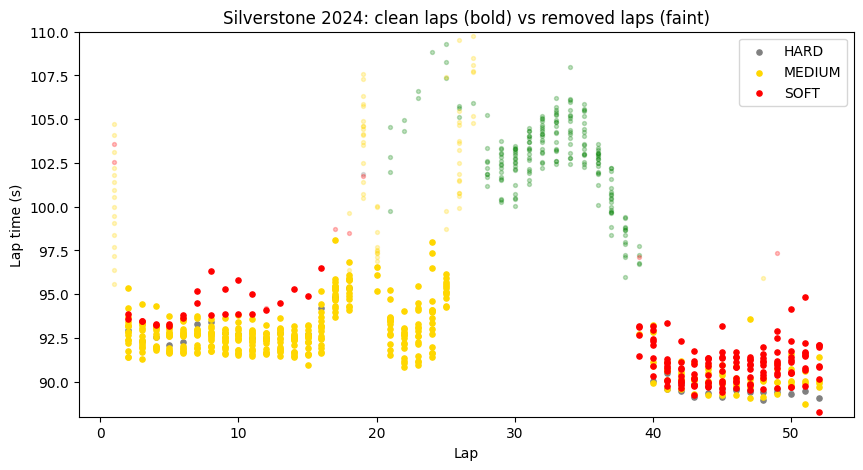

In [8]:
import matplotlib.pyplot as plt

# 1. any safety car / VSC / yellow flags?
sc = rc[rc["message"].str.contains("SAFETY CAR|VSC|VIRTUAL", case=False, na=False)]
print("Safety car / VSC messages:", len(sc))
print(sc[["lap_number", "message"]].head(10).to_string())
yel = rc[rc["flag"].isin(["YELLOW", "DOUBLE YELLOW"])]
print("Yellow flag messages:", len(yel), "| laps affected:", sorted(yel["lap_number"].dropna().unique().astype(int)))
print()

# 2. flag laps to remove
d = df.copy()
pit_laps = set(zip(pits["driver_number"], pits["lap_number"]))
d["is_in_lap"] = [(a, b) in pit_laps for a, b in zip(d["driver_number"], d["lap_number"])]
sc_laps = set(sc["lap_number"].dropna().astype(int))
d["sc_lap"] = d["lap_number"].isin(sc_laps)

keep = (
    (d["lap_number"] > 1)
    & (~d["is_pit_out_lap"].astype(bool))
    & (~d["is_in_lap"])
    & (~d["sc_lap"])
    & (d["compound"].isin(["SOFT", "MEDIUM", "HARD"]))
)
clean = d[keep].copy()

# 3. drop unusually slow laps (more than 4% slower than that driver's stint median)
med = clean.groupby(["driver_number", "stint"])["lap_duration"].transform("median")
clean = clean[clean["lap_duration"] < 1.04 * med].copy()

print("Laps before:", len(d), "| after cleaning:", len(clean))
print(clean["compound"].value_counts())
print("Lap numbers kept:", clean["lap_number"].min(), "to", clean["lap_number"].max())

# 4. picture
colors = {"SOFT": "red", "MEDIUM": "gold", "HARD": "grey", "INTERMEDIATE": "green"}
fig, ax = plt.subplots(figsize=(10, 5))
for c, g in d.groupby("compound"):
    ax.scatter(g["lap_number"], g["lap_duration"], s=8, alpha=0.25, color=colors[c])
for c, g in clean.groupby("compound"):
    ax.scatter(g["lap_number"], g["lap_duration"], s=14, color=colors[c], label=c)
ax.set_ylim(88, 110)
ax.set_xlabel("Lap")
ax.set_ylabel("Lap time (s)")
ax.set_title("Silverstone 2024: clean laps (bold) vs removed laps (faint)")
ax.legend()
plt.show()

In [7]:
import requests, time
import pandas as pd
import numpy as np

BASE = "https://api.openf1.org/v1"
SK = 9558

def get(endpoint, **params):
    for attempt in range(5):
        r = requests.get(f"{BASE}/{endpoint}", params={"session_key": SK, **params})
        if r.status_code == 200:
            return pd.DataFrame(r.json())
        time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"{endpoint} failed: {r.status_code}")

laps    = get("laps")
stints  = get("stints")
pits    = get("pit")
drivers = get("drivers")
rc      = get("race_control")

print("laps:", laps.shape, "| stints:", stints.shape,
      "| pits:", pits.shape, "| drivers:", drivers.shape)

laps = laps.dropna(subset=["lap_duration"]).copy()
rows = []
for _, s in stints.iterrows():
    ls, le = s["lap_start"], s["lap_end"]
    if pd.isna(ls) or pd.isna(le):
        continue
    mask = (laps["driver_number"] == s["driver_number"])
    mask = mask & (laps["lap_number"] >= ls) & (laps["lap_number"] <= le)
    sub = laps[mask].copy()
    sub["compound"] = s["compound"]
    sub["stint"] = s["stint_number"]
    sub["tyre_age"] = s["tyre_age_at_start"] + (sub["lap_number"] - ls)
    rows.append(sub)
df = pd.concat(rows)

dr = drivers[["driver_number", "name_acronym", "team_name"]]
dr = dr.drop_duplicates("driver_number")
df = df.merge(dr, on="driver_number", how="left")

cols = ["name_acronym", "lap_number", "lap_duration",
        "compound", "stint", "tyre_age", "is_pit_out_lap"]
print(df[cols].head(12))
print()
print(df["compound"].value_counts())
print()

inter = df[df["compound"] == "INTERMEDIATE"]
print("Intermediate laps:", inter["lap_number"].min(), "to", inter["lap_number"].max())
print()

flags = rc[rc["category"].isin(["SafetyCar", "Flag"])]
rc_cols = ["lap_number", "category", "flag", "message"]
print(flags[rc_cols].head(25).to_string())

laps: (962, 16) | stints: (65, 8) | pits: (45, 8) | drivers: (20, 12)
   name_acronym  lap_number  lap_duration compound  stint  tyre_age  \
0           BOT           1       104.744   MEDIUM      1       0.0   
1           BOT           2        95.368   MEDIUM      1       1.0   
2           BOT           3        94.447   MEDIUM      1       2.0   
3           BOT           4        94.322   MEDIUM      1       3.0   
4           BOT           5        93.768   MEDIUM      1       4.0   
5           BOT           6        93.460   MEDIUM      1       5.0   
6           BOT           7        93.648   MEDIUM      1       6.0   
7           BOT           8        93.561   MEDIUM      1       7.0   
8           BOT           9        93.645   MEDIUM      1       8.0   
9           BOT          10        93.787   MEDIUM      1       9.0   
10          BOT          11        93.561   MEDIUM      1      10.0   
11          BOT          12        93.269   MEDIUM      1      11.0   

    is

In [4]:
import requests, pandas as pd

BASE = "https://api.openf1.org/v1"

# 1. Find the Silverstone 2024 race
sess = requests.get(f"{BASE}/sessions", params={
    "year": 2024, "session_name": "Race", "circuit_short_name": "Silverstone"}).json()
print(sess)

[{'session_key': 9558, 'session_type': 'Race', 'session_name': 'Race', 'date_start': '2024-07-07T14:00:00+00:00', 'date_end': '2024-07-07T16:00:00+00:00', 'meeting_key': 1240, 'circuit_key': 2, 'circuit_short_name': 'Silverstone', 'country_key': 2, 'country_code': 'GBR', 'country_name': 'United Kingdom', 'location': 'Silverstone', 'gmt_offset': '01:00:00', 'year': 2024, 'is_cancelled': False}]


In [1]:
!pip install fastf1 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.0/136.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 47.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.7/424.7 kB 38.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 7.8 MB/s eta 0:00:00
